# Базовое ДЗ (обязательная часть)

In [3]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
  Using cached kagglehub-1.0.3-py3-none-any.whl.metadata (40 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
  Using cached kagglesdk-0.1.38-py3-none-any.whl.metadata (13 kB)
Using cached kagglehub-1.0.3-py3-none-any.whl (73 kB)
Using cached kagglesdk-0.1.38-py3-none-any.whl (290 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

   ---------------------------------------- 0/3 [certifi]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

100%|██████████| 22.0M/22.0M [00:02<00:00, 9.89MB/s]

Extracting files...


Path to dataset files: C:\Users\Дима\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1


In [5]:
import os

for dirpath, dirnames, filenames in os.walk(path):
    depth = dirpath.replace(path, "").count(os.sep)
    if depth <= 2:  # не углубляемся слишком сильно
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath)}/")
        if filenames:
            print(f"{indent}  └── файлов: {len(filenames)}, примеры: {filenames[:3]}")

1/
  └── файлов: 4, примеры: ['t10k-images.idx3-ubyte', 't10k-labels.idx1-ubyte', 'train-images.idx3-ubyte']
  t10k-images-idx3-ubyte/
    └── файлов: 1, примеры: ['t10k-images-idx3-ubyte']
  t10k-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['t10k-labels-idx1-ubyte']
  train-images-idx3-ubyte/
    └── файлов: 1, примеры: ['train-images-idx3-ubyte']
  train-labels-idx1-ubyte/
    └── файлов: 1, примеры: ['train-labels-idx1-ubyte']


In [6]:
import os
import struct
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

ROOT = path

def read_idx_images(path):
    """Читает IDX-файл с изображениями → массив (N, rows*cols)."""
    with open(path, 'rb') as f:
        magic, n, rows, cols = struct.unpack(">IIII", f.read(16))
        # Проверяем магическое число (2051 = 0x00000803)
        assert magic == 2051, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
        data = data.reshape(n, rows * cols)
    return data.astype(np.float32)

def read_idx_labels(path):
    """Читает IDX-файл с метками → массив (N,)."""
    with open(path, 'rb') as f:
        magic, n = struct.unpack(">II", f.read(8))
        # Проверяем магическое число (2049 = 0x00000801)
        assert magic == 2049, f"Неверный magic number в {path}: {magic}"
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(int)

def load_mnist_idx(root_dir):
    """
    Загружает MNIST из IDX-файлов в стиле MedMNIST:
    возвращает (X_train, y_train, X_val, y_val, X_test, y_test).

    MNIST: 60000 train + 10000 test. Отделяем 10% от train под validation.
    """
    root = Path(root_dir)

    # Ищем файлы в корне (могут быть с дефисами или подчёркиваниями)
    def find_file(*candidates):
        for name in candidates:
            p = root / name
            if p.exists():
                return p
            # ищем рекурсивно на случай вложенных папок
            for sub in root.rglob(name):
                return sub
        raise FileNotFoundError(
            f"Не найден файл среди: {candidates} в {root_dir}"
        )

    train_images = find_file(
        "train-images.idx3-ubyte",
        "train-images-idx3-ubyte",
    )
    train_labels = find_file(
        "train-labels.idx1-ubyte",
        "train-labels-idx1-ubyte",
    )
    test_images = find_file(
        "t10k-images.idx3-ubyte",
        "t10k-images-idx3-ubyte",
    )
    test_labels = find_file(
        "t10k-labels.idx1-ubyte",
        "t10k-labels-idx1-ubyte",
    )

    print(f"Train images: {train_images}")
    print(f"Train labels: {train_labels}")
    print(f"Test  images: {test_images}")
    print(f"Test  labels: {test_labels}")

    # Загружаем
    X_train_full = read_idx_images(train_images)
    y_train_full = read_idx_labels(train_labels)
    X_test       = read_idx_images(test_images)
    y_test       = read_idx_labels(test_labels)

    # Отделяем validation (10% от train, стратифицированно)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.1,
        random_state=42,
        stratify=y_train_full,
    )

    # Нормализация пикселей: [0, 255] → [0, 1]
    # В MedMNIST данные уже в [0, 1], приводим MNIST к тому же виду
    X_train = X_train / 255.0
    X_val   = X_val   / 255.0
    X_test  = X_test  / 255.0

    print(f"\nTrain:      X={X_train.shape}, y={y_train.shape}")
    print(f"Validation: X={X_val.shape},   y={y_val.shape}")
    print(f"Test:       X={X_test.shape},  y={y_test.shape}")

    return X_train, y_train, X_val, y_val, X_test, y_test

In [7]:
X_train, y_train, X_val, y_val, X_test, y_test = load_mnist_idx(ROOT)

Train images: C:\Users\Дима\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\train-images.idx3-ubyte
Train labels: C:\Users\Дима\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\train-labels.idx1-ubyte
Test  images: C:\Users\Дима\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\t10k-images.idx3-ubyte
Test  labels: C:\Users\Дима\.cache\kagglehub\datasets\hojjatk\mnist-dataset\versions\1\t10k-labels.idx1-ubyte

Train:      X=(54000, 784), y=(54000,)
Validation: X=(6000, 784),   y=(6000,)
Test:       X=(10000, 784),  y=(10000,)


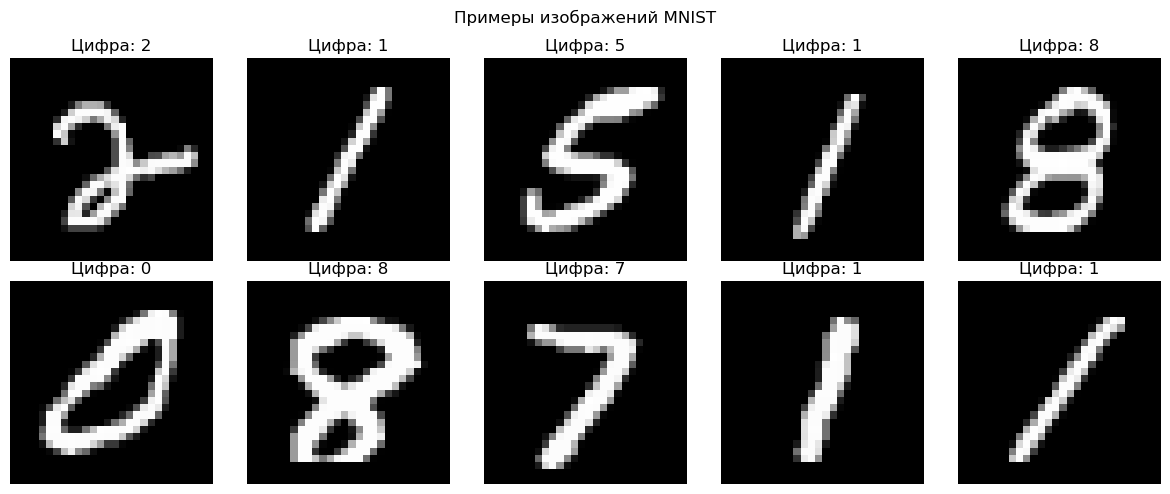

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Цифра: {y_train[i]}")
    ax.axis("off")

plt.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

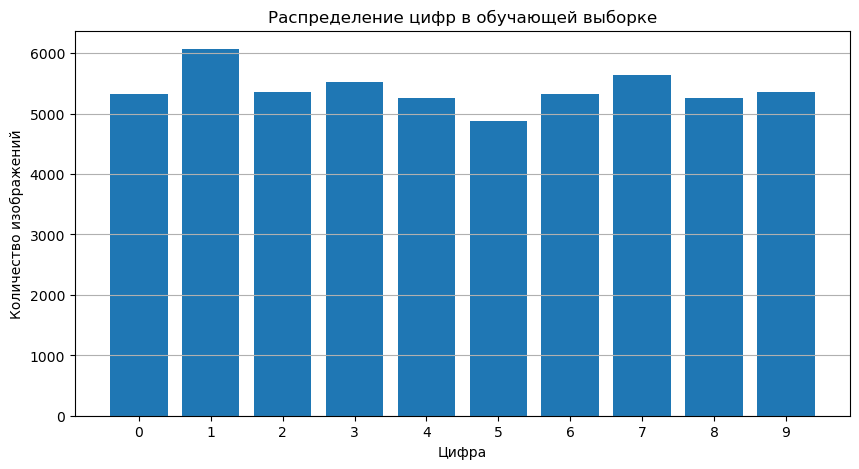

Количество изображений каждой цифры:
Цифра 0: 5331
Цифра 1: 6068
Цифра 2: 5362
Цифра 3: 5518
Цифра 4: 5258
Цифра 5: 4879
Цифра 6: 5326
Цифра 7: 5638
Цифра 8: 5266
Цифра 9: 5354


In [9]:
import numpy as np

digits = np.arange(10)

train_counts = np.bincount(y_train)

plt.figure(figsize=(10, 5))
plt.bar(digits, train_counts)

plt.xlabel("Цифра")
plt.ylabel("Количество изображений")
plt.title("Распределение цифр в обучающей выборке")
plt.xticks(digits)
plt.grid(axis="y")
plt.show()

print("Количество изображений каждой цифры:")
for i in range(10):
    print(f"Цифра {i}: {train_counts[i]}")

Дерево

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_full.predict(X_train))
val_acc = accuracy_score(y_val, tree_full.predict(X_val))

print(f"Дерево без ограничений: train={train_acc:.3f}, val={val_acc:.3f}")

tree_small = DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42)
tree_small.fit(X_train, y_train)

train_acc = accuracy_score(y_train, tree_small.predict(X_train))
val_acc = accuracy_score(y_val, tree_small.predict(X_val))

print(f"Дерево с глубиной 7: train={train_acc:.3f}, val={val_acc:.3f}")

Дерево без ограничений: train=1.000, val=0.875
Дерево с глубиной 7: train=0.807, val=0.794


Случайный Лес

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

train_acc = accuracy_score(y_train, rf.predict(X_train))
val_acc = accuracy_score(y_val, rf.predict(X_val))

print(f"Random Forest: train={train_acc:.3f}, val={val_acc:.3f}")

Random Forest: train=1.000, val=0.968


Градиентный бустинг

In [12]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=10, learning_rate=0.1, max_depth=3, random_state=42)
gb.fit(X_train[:5000], y_train[:5000])

train_acc = accuracy_score(y_train[:5000], gb.predict(X_train[:5000]))
val_acc = accuracy_score(y_val, gb.predict(X_val))

print(f"Gradient Boosting: train={train_acc:.3f}, val={val_acc:.3f}")

Gradient Boosting: train=0.867, val=0.821


Сравнение результатов

In [13]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Decision Tree": tree_full,
    "Decision Tree (depth=7)": tree_small,
    "Random Forest": rf,
    "Gradient Boosting": gb
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"{name}: accuracy={acc:.3f}, F1={f1:.3f}")

Decision Tree: accuracy=0.879, F1=0.878
Decision Tree (depth=7): accuracy=0.799, F1=0.796
Random Forest: accuracy=0.968, F1=0.968
Gradient Boosting: accuracy=0.835, F1=0.833


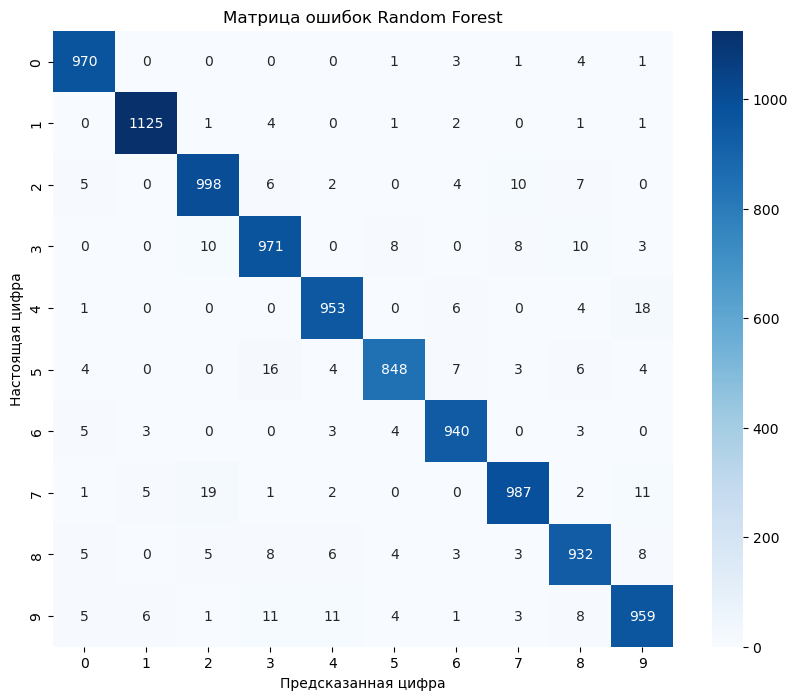

In [14]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = rf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Предсказанная цифра")
plt.ylabel("Настоящая цифра")
plt.title("Матрица ошибок Random Forest")
plt.show()

Вывод: Лучший результат показал Random Forest с точностью 96,8%, остальные модели справились хуже.